# Analisis Credit Risk: Prediksi Gagal Bayar Pinjaman

**Masalah bisnis:** lembaga pinjaman ingin tahu calon peminjam mana yang berisiko gagal bayar sebelum pinjamannya disetujui.

**Tujuan:** membuat model klasifikasi untuk memprediksi `loan_status` (1 = gagal bayar, 0 = lancar).

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score,roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

## 1. Mengumpulkan Data

Data diambil dari Credit Risk Dataset OpenML dalam bentuk file CSV.

https://www.openml.org/search?type=data&sort=runs&id=43454

In [36]:
df = pd.read_csv(r"D:\kuliah\Bootcamp Digisloka\BNSP\Project\credit_risk_dataset.csv")
df.shape

(32581, 12)

In [37]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Penjelasan kolom:

| Kolom | Arti |
| --- | --- |
| person_age | umur peminjam |
| person_income | pendapatan per tahun |
| person_home_ownership | status rumah (sewa, milik, KPR, lainnya) |
| person_emp_length | lama bekerja (tahun) |
| loan_intent | tujuan pinjaman |
| loan_grade | peringkat pinjaman A (terbaik) sampai G |
| loan_amnt | jumlah pinjaman |
| loan_int_rate | suku bunga |
| loan_status | **target**: 1 = gagal bayar, 0 = lancar |
| loan_percent_income | pinjaman dibagi pendapatan |
| cb_person_default_on_file | pernah gagal bayar sebelumnya (Y/N) |
| cb_person_cred_hist_length | lama riwayat kredit (tahun) |

## 2. Menelaah Data

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [39]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64


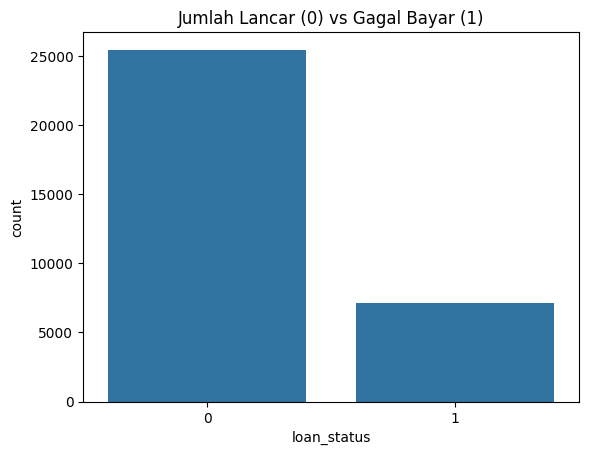

In [40]:
print(df['loan_status'].value_counts())
print(df['loan_status'].value_counts(normalize=True))

sns.countplot(data=df, x='loan_status')
plt.title('Jumlah Lancar (0) vs Gagal Bayar (1)')
plt.show()

Data **tidak seimbang**: sekitar 78% lancar dan 22% gagal bayar.

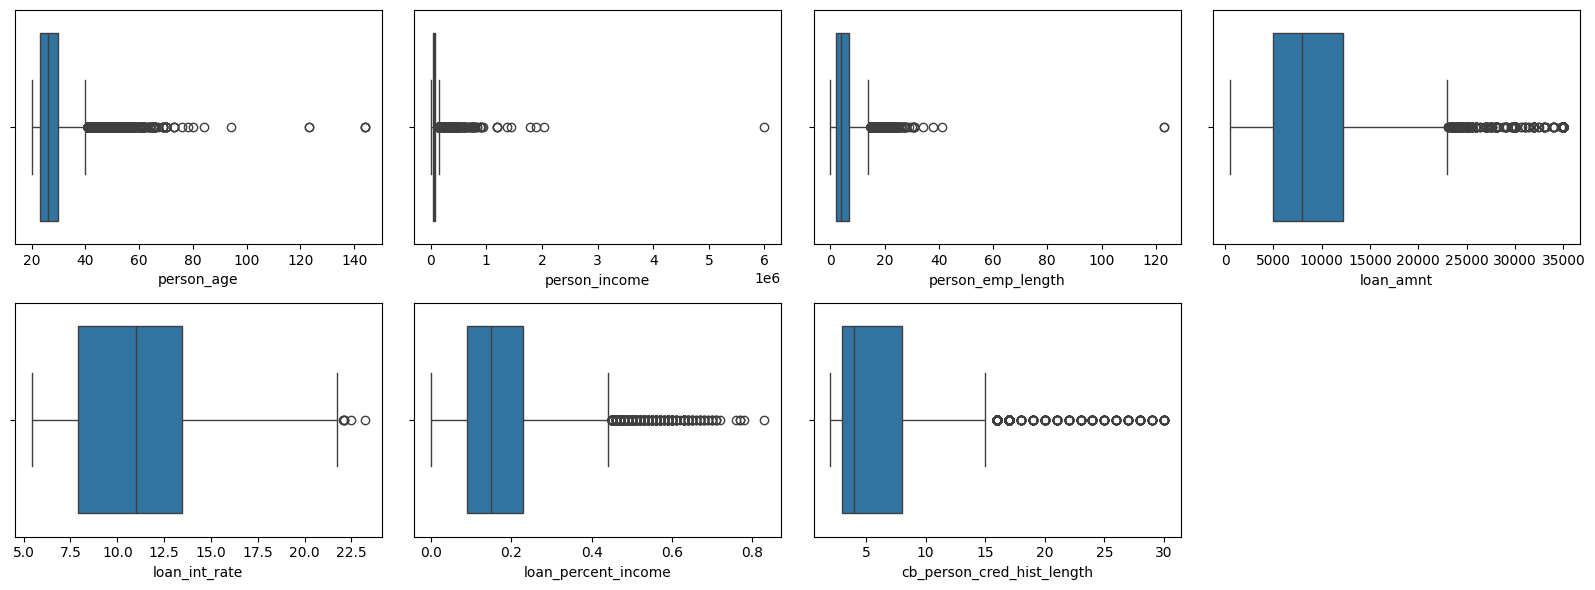

In [41]:
# boxplot untuk melihat outlier
kolom_angka = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
               'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
axes = axes.flatten()
for i, col in enumerate(kolom_angka):
    sns.boxplot(x=df[col], ax=axes[i])
axes[7].axis('off')
plt.tight_layout()
plt.show()

Ada outlier yang tidak masuk akal: umur sampai 144 tahun dan lama bekerja sampai 123 tahun. Ini kemungkinan salah input. Pendapatan sampai 6 juta juga sangat tinggi, tapi masih mungkin benar.

In [42]:
# persentase gagal bayar per kategori
for col in ['loan_grade', 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file']:
    print(df.groupby(col)['loan_status'].mean().round(3))
    print()

loan_grade
A    0.100
B    0.163
C    0.207
D    0.590
E    0.644
F    0.705
G    0.984
Name: loan_status, dtype: float64

person_home_ownership
MORTGAGE    0.126
OTHER       0.308
OWN         0.075
RENT        0.316
Name: loan_status, dtype: float64

loan_intent
DEBTCONSOLIDATION    0.286
EDUCATION            0.172
HOMEIMPROVEMENT      0.261
MEDICAL              0.267
PERSONAL             0.199
VENTURE              0.148
Name: loan_status, dtype: float64

cb_person_default_on_file
N    0.184
Y    0.378
Name: loan_status, dtype: float64



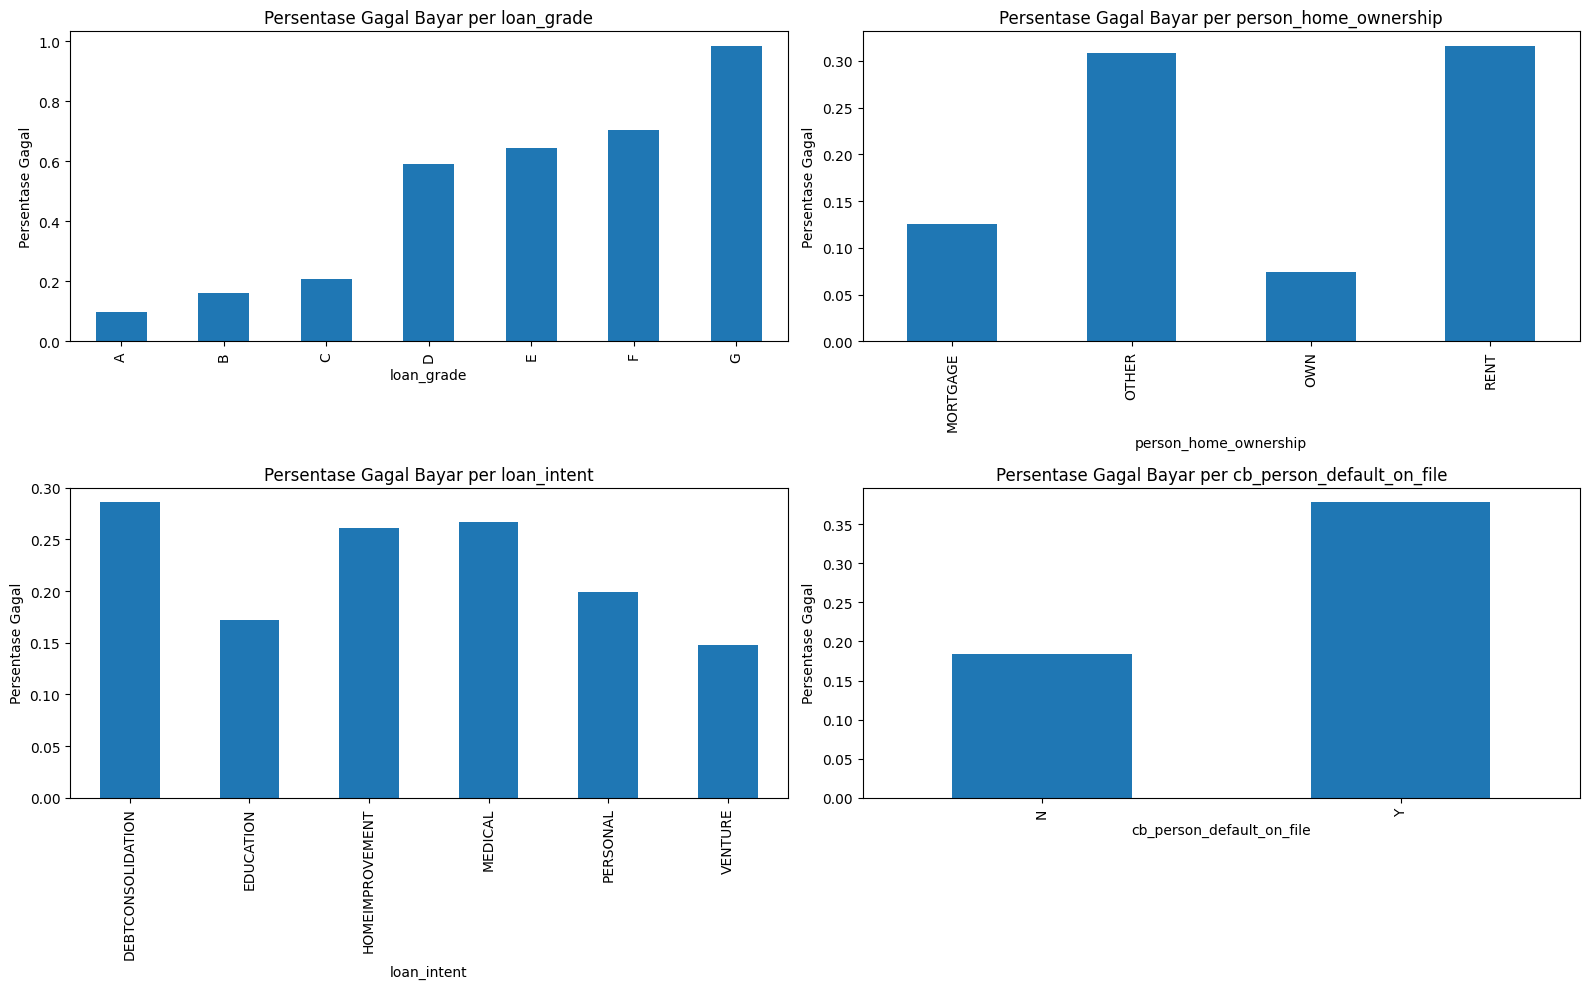

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(['loan_grade', 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file']):
    df.groupby(col)['loan_status'].mean().plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Persentase Gagal Bayar per {col}')
    axes[i].set_ylabel('Persentase Gagal')

plt.tight_layout()
plt.show()
    

Semakin buruk grade-nya (A ke G), semakin tinggi peluang gagal bayar. Peminjam yang pernah gagal bayar sebelumnya (Y) juga lebih berisiko, kebanyakan yang gagal juga masih menyewa rumah karena beban bayaran yang ditambah hutang.

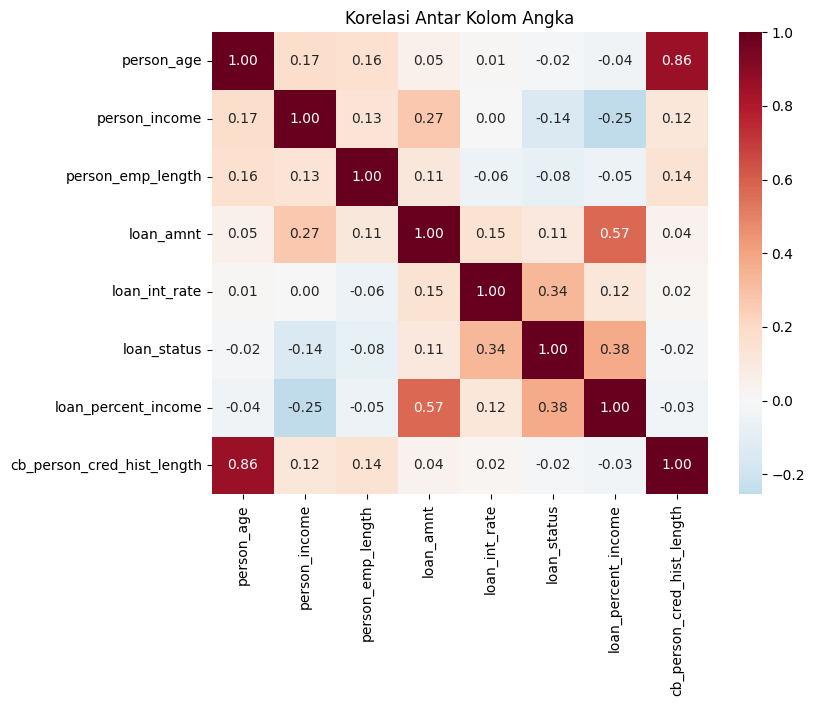

In [44]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Korelasi Antar Kolom Angka')
plt.show()

Kolom yang paling berhubungan dengan gagal bayar adalah `loan_percent_income` dan `loan_int_rate` (positif). Pendapatan berhubungan negatif: makin tinggi pendapatan, makin kecil risikonya.

## 3. Memvalidasi Data

Cek data kosong, data duplikat, dan data yang tidak logis.

In [45]:
print("Data kosong:")
print(df.isnull().sum())
print()
print("Persentase data kosong:")
print((df.isnull().sum() / len(df) * 100).round(2))

Data kosong:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Persentase data kosong:
person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.75
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.56
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64


In [46]:
print("Data duplikat:", df.duplicated().sum())

Data duplikat: 165


In [47]:
# mengatasi outlier
print("Umur > 100 tahun:", (df['person_age'] > 100).sum())
print("Lama kerja lebih dari (umur - 14):", (df['person_emp_length'] > df['person_age'] - 14).sum())
print("Riwayat kredit lebih lama dari umur:", (df['cb_person_cred_hist_length'] > df['person_age']).sum())

Umur > 100 tahun: 5
Lama kerja lebih dari (umur - 14): 2
Riwayat kredit lebih lama dari umur: 0


**Kesimpulan validasi:**

- Ada data kosong di `loan_int_rate` (±9,6%) dan `person_emp_length` (±2,7%). Jumlahnya hanya 12% dari datanya masih cukup untuk dihapus.
- Ada 165 data duplikat → dibuang.
- Ada 7 data tidak logis (umur > 100 atau lama kerja tidak masuk akal) → dibuang karena salah input.
- Data gagal bayar ada lebih dari 7.000 baris, jadi **data cukup** untuk membuat model.

## 4. Menentukan Objek Data

| Kolom | Dipakai? | Alasan |
| --- | --- | --- |
| Data peminjam (umur, pendapatan, rumah, lama kerja) | Ya | Menggambarkan kemampuan bayar |
| Data pinjaman (jumlah, tujuan, grade, bunga) | Ya | Menggambarkan besar risiko pinjaman |
| Riwayat kredit | Ya | Perilaku bayar di masa lalu |
| loan_status | Target | Yang ingin diprediksi |


In [48]:
fitur = ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length',
         'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate',
         'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']
target = 'loan_status'

df = df[fitur + [target]]

## 5. Membersihkan Data

In [49]:
print("Sebelum dibersihkan:", df.shape)

# 1. buang data duplikat
df = df.drop_duplicates()
print("Setelah buang duplikat:", df.shape)

# 2. buang data yang tidak logis
data_salah = (df['person_age'] > 100) | (df['person_emp_length'] > df['person_age'] - 14)
df = df[~data_salah]
print("Setelah buang data tidak logis:", df.shape)

Sebelum dibersihkan: (32581, 12)
Setelah buang duplikat: (32416, 12)
Setelah buang data tidak logis: (32409, 12)


In [50]:
df = df.dropna()

## 6. Mengkonstruksi Data

**Encoding** (mengubah huruf menjadi angka):
- `loan_grade` dan `cb_person_default_on_file` punya urutan, jadi diubah manual (A=0 ... G=6, N=0, Y=1).
- `person_home_ownership` dan `loan_intent` tidak punya urutan, jadi pakai one-hot encoding (`get_dummies`).

In [51]:
# encoding manual untuk kolom yang punya urutan
df['loan_grade'] = df['loan_grade'].map({'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6})
df['cb_person_default_on_file'] = df['cb_person_default_on_file'].map({'N': 0, 'Y': 1})

# one-hot untuk kolom yang tidak punya urutan
df = pd.get_dummies(df, columns=['person_home_ownership', 'loan_intent'], drop_first=True, dtype=int)

df.head()

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
1,21,9600,5.0,1,1000,11.14,0.10,0,2,0,0,1,0,1,0,0,0,0
2,25,9600,1.0,2,5500,12.87,0.57,0,3,1,0,0,0,0,0,1,0,0
3,23,65500,4.0,2,35000,15.23,0.53,0,2,1,0,0,1,0,0,1,0,0
4,24,54400,8.0,2,35000,14.27,0.55,1,4,1,0,0,1,0,0,1,0,0
5,21,9900,2.0,0,2500,7.14,0.25,0,2,1,0,1,0,0,0,0,0,1


## 7. Menentukan Label Data

Label = `loan_status`. Nilai 1 artinya peminjam gagal bayar, 0 artinya lancar. Cek apakah isinya hanya 0 dan 1, lalu lihat perbandingannya.

In [52]:
X = df.drop(columns='loan_status')
y = df['loan_status']

print("Isi label:", y.unique())
print(y.value_counts())
print("Perbandingan lancar : gagal bayar =", round(y.value_counts()[0] / y.value_counts()[1], 2), ": 1")

Isi label: [0 1]
loan_status
0    22308
1     6187
Name: count, dtype: int64
Perbandingan lancar : gagal bayar = 3.61 : 1


Perbandingannya sekitar 3,6 : 1 (tidak seimbang). Karena itu model memakai `class_weight='balanced'` supaya kelas gagal bayar tidak diabaikan.

## 8. Membangun Model

**Skenario pengujian:**
1. Data dibagi 80% train dan 20% test dengan `stratify=y` agar perbandingan kelasnya sama.
2. Data diskalakan dengan StandardScaler (fit di train saja).
3. Lima model dibandingkan: Logistic Regression, Decision Tree, Random Forest, Naive Bayes, XGBoost.

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (22796, 17)
Test : (5699, 17)


In [54]:
print("Data kosong di train:", X_train.isnull().sum().sum())
print("Data kosong di test :", X_test.isnull().sum().sum())

Data kosong di train: 0
Data kosong di test : 0


In [55]:
# cek apakah data kosong hilang secara acak
baris_kosong = df[['person_emp_length', 'loan_int_rate']].isnull().any(axis=1)

print("Baris dengan data kosong:", baris_kosong.sum(), f"({baris_kosong.mean()*100:.1f}%)")
print("Gagal bayar di baris kosong  :", round(df[baris_kosong]['loan_status'].mean(), 3))
print("Gagal bayar di baris lengkap :", round(df[~baris_kosong]['loan_status'].mean(), 3))

Baris dengan data kosong: 0 (0.0%)
Gagal bayar di baris kosong  : nan
Gagal bayar di baris lengkap : 0.217


In [56]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [57]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,class_weight='balanced', random_state=42),
    "Naive Bayes": GaussianNB(priors=[0.5,0.5]),
    "Xgboost": XGBClassifier(n_estimators = 200,  random_state=42)
}

result = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred_train = model.predict(X_train_scaled)

    result.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Test": f1_score(y_test, y_pred),
        "F1 Train": f1_score(y_train, y_pred_train),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

result_df = pd.DataFrame(result)
result_df['Selisih F1 (Train - Test)'] = result_df['F1 Train'] - result_df['F1 Test']
result_df.sort_values(by='F1 Test', ascending=False).round(3)

,Model,Accuracy,Precision,Recall,F1 Test,F1 Train,ROC-AUC,Selisih F1 (Train - Test)
4,Xgboost,0.939,0.937,0.770,0.845,0.953,0.954,0.108
2,Random Forest,0.937,0.976,0.729,0.835,1.000,0.942,0.165
1,Decision Tree,0.897,0.749,0.787,0.768,1.000,0.857,0.232
0,Logistic Regression,0.793,0.516,0.781,0.621,0.621,0.868,-0.000
3,Naive Bayes,0.756,0.463,0.792,0.585,0.579,0.840,-0.005


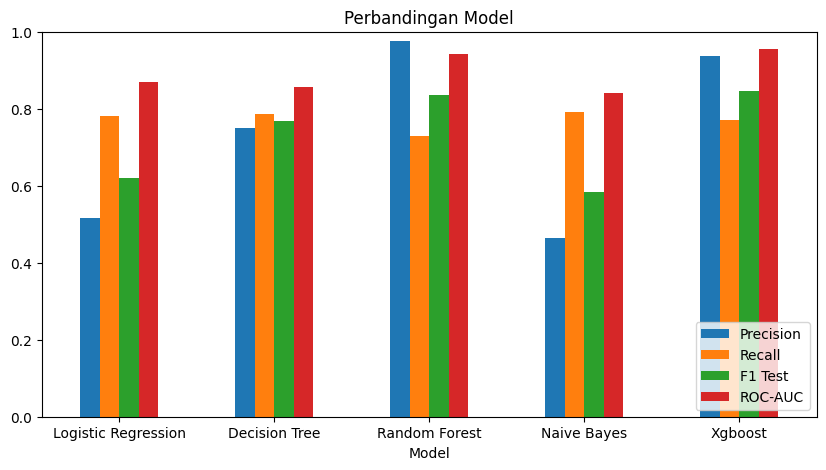

In [58]:
result_df.set_index('Model')[['Precision', 'Recall', 'F1 Test', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5))
plt.title('Perbandingan Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

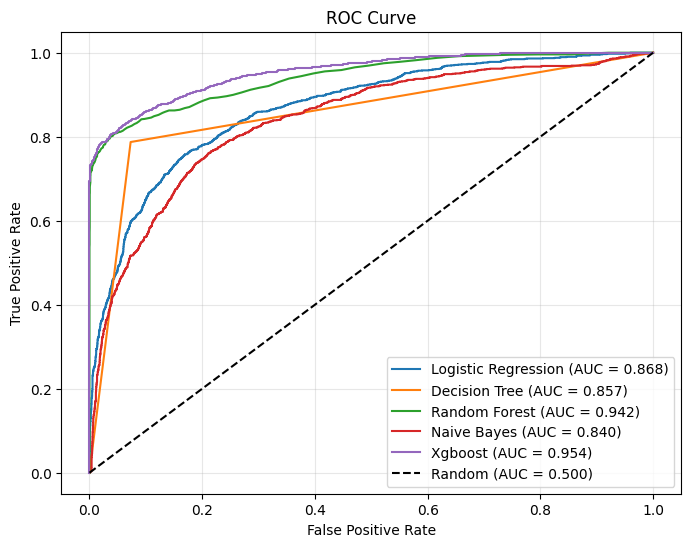

In [59]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]   # hitung ulang untuk tiap model
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.500)')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


## 9. Mengevaluasi Hasil Pemodelan

In [60]:
best_model = models["Xgboost"]

y_pred = best_model.predict(X_test_scaled)
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Lancar', 'Gagal Bayar']))
print("ROC-AUC :", round(roc_auc_score(y_test, y_proba), 3))
print("F1 Train:", round(f1_score(y_train, best_model.predict(X_train_scaled)), 3))
print("F1 Test :", round(f1_score(y_test, y_pred), 3))


              precision    recall  f1-score   support

      Lancar       0.94      0.99      0.96      4462
 Gagal Bayar       0.94      0.77      0.85      1237

    accuracy                           0.94      5699
   macro avg       0.94      0.88      0.90      5699
weighted avg       0.94      0.94      0.94      5699

ROC-AUC : 0.954
F1 Train: 0.953
F1 Test : 0.845


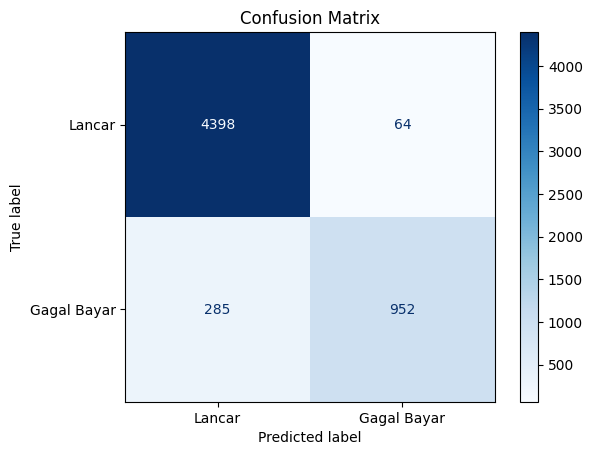

In [61]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Lancar', 'Gagal Bayar'], cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

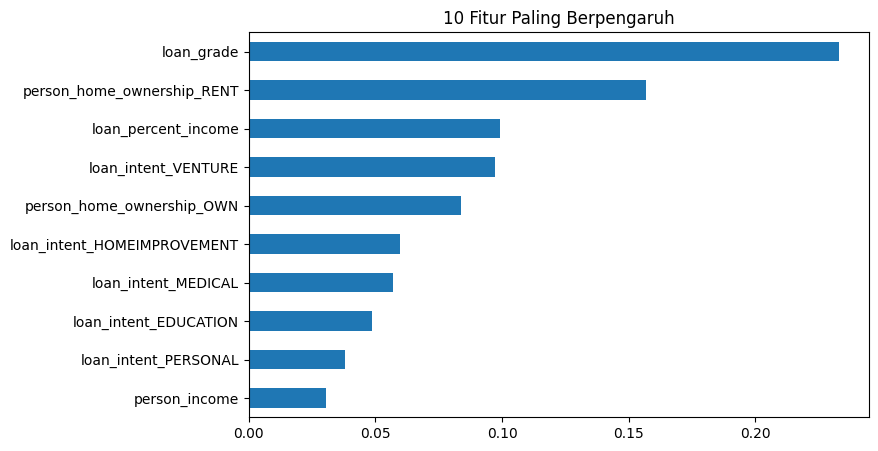

In [62]:
# fitur yang paling berpengaruh
importance = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values()
importance.tail(10).plot(kind='barh', figsize=(8, 5))
plt.title('10 Fitur Paling Berpengaruh')
plt.show()

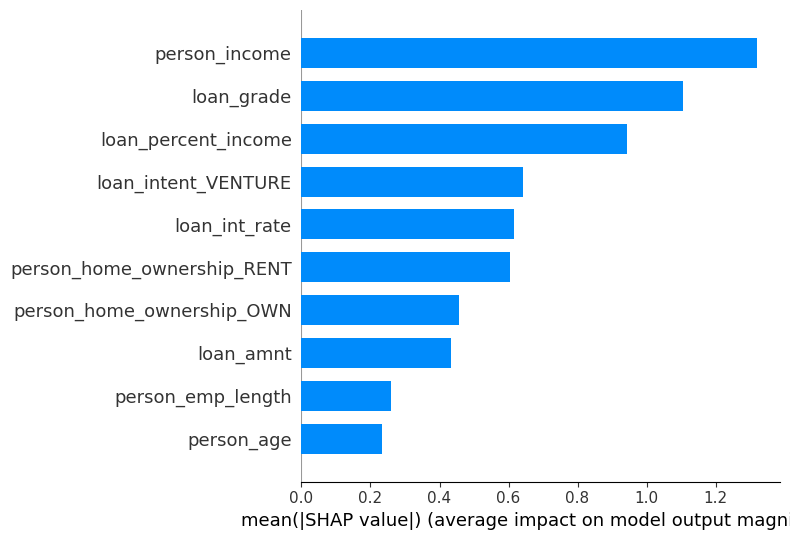

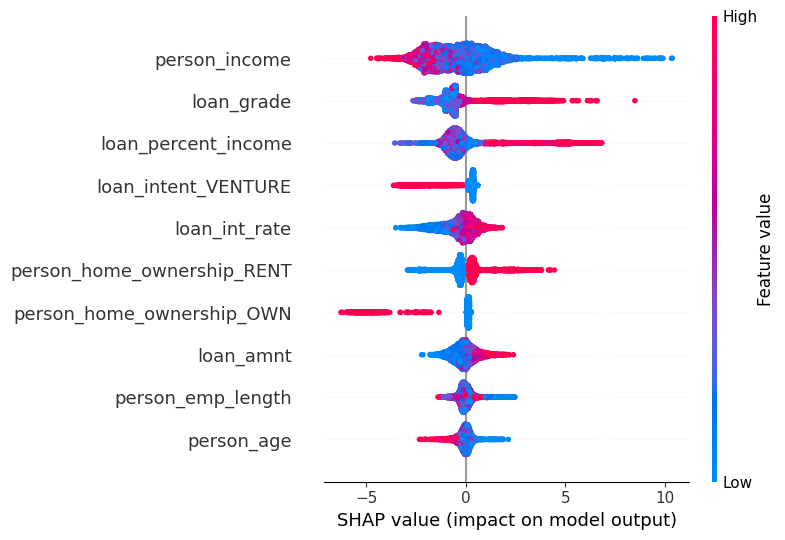

In [63]:
import shap

# ubah ke DataFrame supaya nama kolom muncul di grafik
X_test_df = pd.DataFrame(X_test_scaled, columns=X_train.columns)

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_df)

# 1. ranking fitur (setara feature importance)
shap.summary_plot(shap_values, X_test_df, plot_type='bar', max_display=10)

# 2. ranking + arah pengaruh
shap.summary_plot(shap_values, X_test_df, max_display=10)


## Kesimpulan

1. **Data:** Dari 32.581 data awal, 172 data dibuang karena duplikat (165) dan tidak logis (7),
   lalu 3.914 data yang memiliki nilai kosong dihapus. Data akhir berjumlah 28.495 baris
   (22.308 lancar dan 6.187 gagal bayar), dibagi menjadi 80% data train dan 20% data test.

2. **Model terbaik:** XGBoost dipilih karena memiliki F1-Score (0,845) dan ROC-AUC (0,955) tertinggi
   dibanding Logistic Regression, Decision Tree, Random Forest, dan Naive Bayes. Selisih F1 train dan test
   juga paling kecil di antara model berbasis tree (0,108), sehingga tidak terjadi overfitting berat seperti
   Random Forest dan Decision Tree (F1 train = 1,000).

3. **Hasil model:** XGBoost menghasilkan accuracy 0,939, precision 0,954, recall 0,757, F1-Score 0,845,
   dan ROC-AUC 0,954. Artinya:
   - Dari seluruh peminjam yang benar-benar gagal bayar, sekitar 76% berhasil terdeteksi oleh model.
   - Dari peminjam yang diprediksi gagal bayar, 95% memang benar gagal bayar, sehingga model jarang
     salah menandai peminjam yang lancar.
   - ROC-AUC 0,955 menunjukkan model sangat baik dalam membedakan peminjam lancar dan gagal bayar.
   - Accuracy tidak dijadikan acuan utama karena data tidak seimbang: model yang selalu menebak
     "lancar" pun sudah mencapai accuracy 78%, tetapi tidak mendeteksi satu pun peminjam gagal bayar.
   Kelemahan model adalah masih ada sekitar 24% peminjam gagal bayar yang lolos terdeteksi.

4. **Faktor risiko utama:** Berdasarkan analisis SHAP, faktor yang paling memengaruhi prediksi gagal bayar
   adalah pendapatan, loan grade, dan porsi pinjaman terhadap pendapatan. Peminjam berisiko lebih tinggi jika
   berpendapatan rendah, memiliki loan grade buruk, porsi pinjaman besar dibanding pendapatan, dan tinggal di
   rumah sewa. Sebaliknya, peminjam yang memiliki rumah sendiri serta mengajukan pinjaman untuk usaha (venture)
   atau pendidikan cenderung lebih kecil risikonya. Temuan ini sejalan dengan hasil EDA.


5. **Rekomendasi:** Model digunakan sebagai alat bantu analis kredit, bukan pengganti keputusan manusia.
   Calon peminjam yang diprediksi berisiko perlu diperiksa lebih teliti sebelum pinjaman disetujui.
   Performa model perlu dipantau secara berkala karena pola data dapat berubah seiring waktu.
